In [113]:
import sys
sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import poisson
from src.plots import plot_poisson_fit

In [114]:

matches = pd.read_csv("../data/processed/matches.csv", parse_dates = ["date"], dtype = {"season": str})
matches = matches[matches["season"] != "2627"]
matches.shape


(3040, 16)

In [115]:
matches.tail()

,date,Home_team,Away_team,Home_goals,Away_goals,Result,Home_shots,Away_shots,Home_shots_on_target,Away_shots_on_target,Home_corners,Away_corners,Home_odd,Draw_odd,Away_odd,season
3035,2026-05-24,Liverpool,Brentford,1,1,D,24,11,8,2,14,2,1.80,4.20,3.80,2526
3036,2026-05-24,Man City,Aston Villa,1,2,A,16,12,3,5,9,4,1.29,6.00,9.00,2526
3037,2026-05-24,Nott'm Forest,Bournemouth,1,1,D,15,17,5,4,6,3,3.30,3.75,2.05,2526
3038,2026-05-24,Sunderland,Chelsea,2,1,H,20,10,2,1,7,7,3.60,3.60,2.00,2526
3039,2026-05-24,Tottenham,Everton,1,0,H,21,8,6,3,6,2,1.91,3.75,3.80,2526


In [116]:
matches.isnull().sum()

date                    0
Home_team               0
Away_team               0
Home_goals              0
Away_goals              0
Result                  0
Home_shots              0
Away_shots              0
Home_shots_on_target    0
Away_shots_on_target    0
Home_corners            0
Away_corners            0
Home_odd                0
Draw_odd                0
Away_odd                0
season                  0
dtype: int64

Home teams make more corners than away teams, the same like goals

In [117]:
matches["All_corners"] = matches["Home_corners"] + matches["Away_corners"]
matches[["Home_corners", "Away_corners", "All_corners"]].describe()

,Home_corners,Away_corners,All_corners
count,3040.000000,3040.000000,3040.000000
mean,5.652632,4.699342,10.351974
std,3.065973,2.812046,3.420386
min,0.000000,0.000000,2.000000
25%,3.000000,3.000000,8.000000
50%,5.000000,4.000000,10.000000
75%,8.000000,6.000000,13.000000
max,17.000000,19.000000,24.000000


In [118]:
mean_corners = matches["All_corners"].mean()
mean_corners

np.float64(10.351973684210526)

In [119]:
max_corners_home = matches["Home_corners"].max()
max_corners_home
max_corners_away = matches["Away_corners"].max()

In [120]:
matches["corners_difference"] = matches["Home_corners"] - matches["Away_corners"]
matches["corners_difference"].mean()

np.float64(0.9532894736842106)

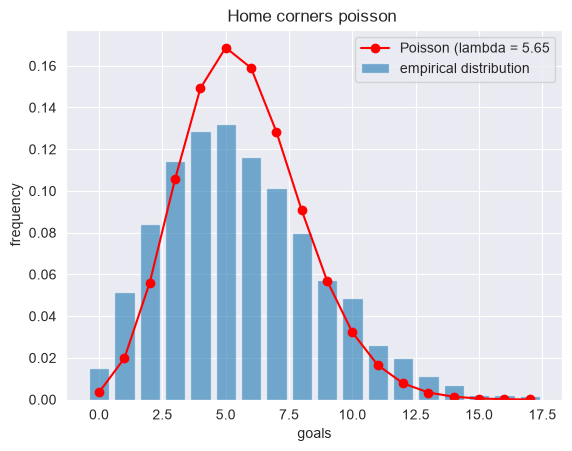

In [121]:


plot_poisson_fit(matches["Home_corners"], "Home corners poisson ", max_corners_home)



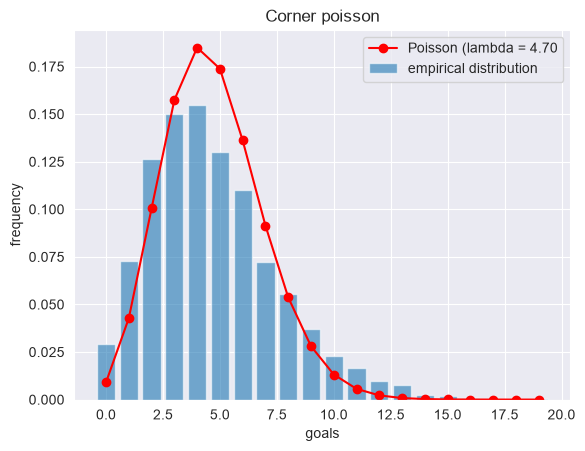

In [122]:
plot_poisson_fit(matches["Away_corners"], "Corner poisson", max_corners_away)

In [123]:
for team in ["Home_corners", "Away_corners"]:
    mean = matches[team].mean()
    var = matches[team].var()
    print(f"{team}: mean : {mean:.3f}, variance : {var:.3f}, variance/mean : {var/mean:.2f}")

Home_corners: mean : 5.653, variance : 9.400, variance/mean : 1.66
Away_corners: mean : 4.699, variance : 7.908, variance/mean : 1.68


ratio between variance/mean is significantly higher than in the goals case

In [124]:
home_team_corners_avg = matches.groupby("Home_team")["Home_corners"].mean().sort_values(ascending= False)  # rożne u siebie
away_team_corners_avg = matches.groupby("Away_team")["Away_corners"].mean().sort_values(ascending= False)  # rożne na wyjażdzie


In [125]:
opponents_corners_when_playing_at_home = matches.groupby("Home_team")["Away_corners"].mean().sort_values(ascending=False)  # avg corners for away team when those teams were playing at home
opponents_corners_when_playing_at_home

Home_team
West Brom           6.631579
Norwich             6.578947
Cardiff             6.105263
Ipswich             5.894737
Southampton         5.596491
Burnley             5.491228
Bournemouth         5.456140
Sheffield United    5.438596
Nott'm Forest       5.421053
Watford             5.175439
Brentford           5.147368
Everton             5.125000
Luton               5.105263
Leicester           5.043860
Sunderland          5.000000
Fulham              4.956140
West Ham            4.953947
Newcastle           4.934211
Wolves              4.868421
Crystal Palace      4.835526
Tottenham           4.769737
Man United          4.756579
Aston Villa         4.684211
Leeds               4.486842
Brighton            4.098684
Chelsea             3.953947
Huddersfield        3.789474
Arsenal             3.723684
Liverpool           3.565789
Man City            2.532895
Name: Away_corners, dtype: float64

<Axes: ylabel='Home_team'>

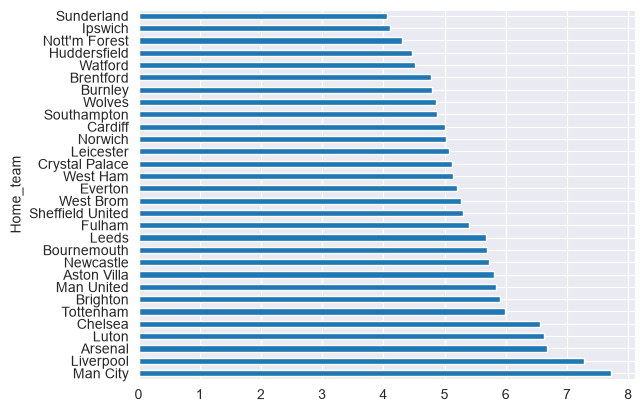

In [126]:
home_team_corners_avg.plot(kind="barh")

<Axes: ylabel='Away_team'>

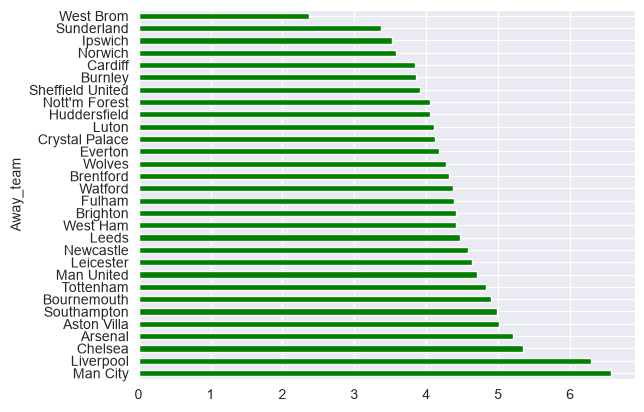

In [127]:
away_team_corners_avg.plot(kind="barh", color = "green")

<Axes: ylabel='Home_team'>

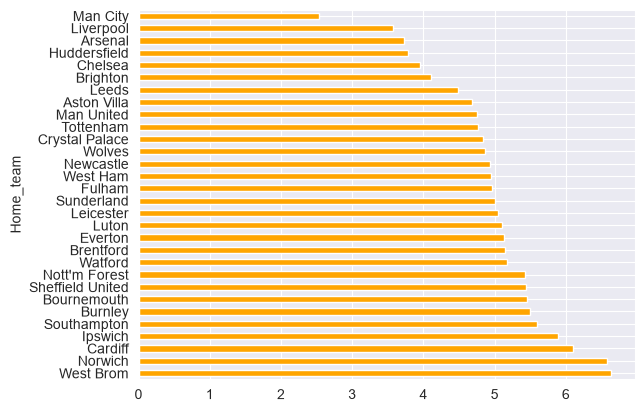

In [128]:
opponents_corners_when_playing_at_home.plot(kind="barh", color = "orange")

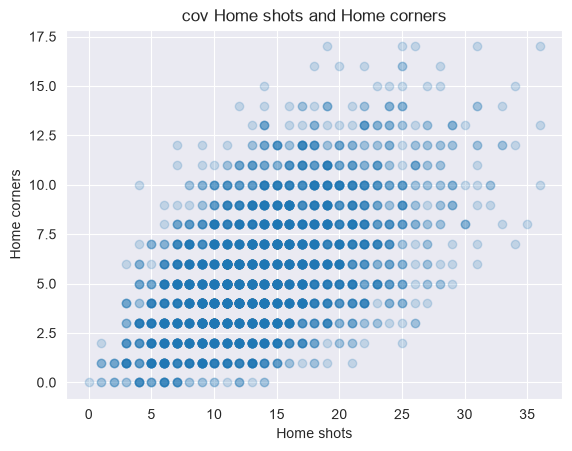

In [129]:
plt.scatter(matches["Home_shots"], matches["Home_corners"], alpha=0.2)
plt.title("cov Home shots and Home corners")
plt.xlabel("Home shots")
plt.ylabel("Home corners")
plt.show()

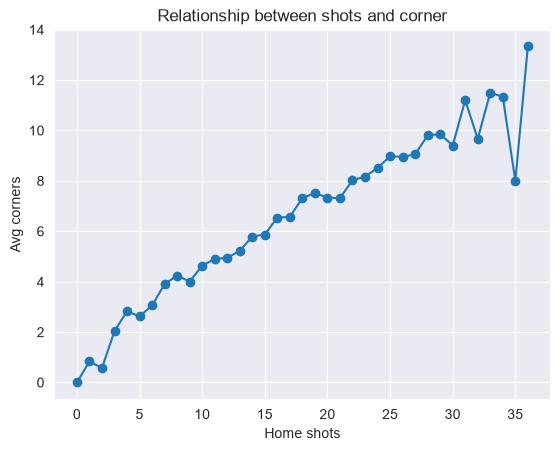

In [130]:
corners_by_shots = matches.groupby("Home_shots")["Home_corners"].mean()
corners_by_shots.plot(kind = "line", marker="o")
plt.xlabel("Home shots")
plt.ylabel("Avg corners")
plt.title("Relationship between shots and corner")
plt.show()

In [131]:
matches["Home_shots"].corr(matches["Home_corners"])


np.float64(0.5462204069204599)

0.54 is pretty strong corellation between shot and corners

In [141]:
matches["Away_shots"].corr(matches["Away_corners"])

np.float64(0.5486603910981672)

The greater the home teams advantage, the more corner they win.

In [133]:
matches["prob_home"] = 1 / matches["Home_odd"]
matches["prob_home"].corr(matches["corners_difference"])


np.float64(0.4765537111790664)

The higher the implied home win probability, the greater the corner difference in favor of the home team
If the probability is between 0 and 20%, the average corner difference is about 3 in favor of the away team

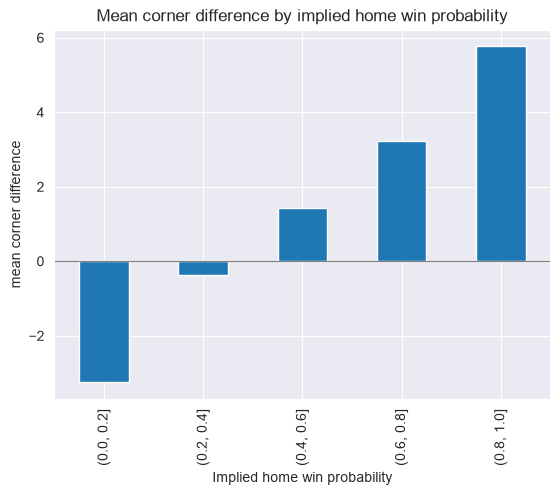

In [140]:
matches["prob_bin"] = pd.cut(matches["prob_home"], bins=[0, 0.2, 0.4, 0.6, 0.8, 1])

diff_by_prob = matches.groupby("prob_bin", observed=True)["corners_difference"].mean()  # difference between home corners and away corners
diff_by_prob.plot(kind="bar")
plt.xlabel("Implied home win probability")
plt.title("Mean corner difference by implied home win probability")
plt.ylabel("mean corner difference")
plt.axhline(0, color ="grey", linewidth = 0.8)
plt.show()